In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

In [ ]:
df = pd.read_csv('/content/posts_short.csv')
df.head()

,Unnamed: 0,id,post_type_id,accepted_answer_id,parent_id,creation_date,score,view_count,owner_user_id,tags,answer_count,comment_count,favorite_count,community_owned_date
0,0,4.0,1.0,7.0,-999.0,2008-07-31T21:42:52.667,573.0,37080.0,8.0,<c#><floating-point><type-conversion><double><...,13.0,1.0,41.0,2012-10-31T16:42:47.213
1,1,6.0,1.0,31.0,-999.0,2008-07-31T22:08:08.620,256.0,16306.0,9.0,<html><css><css3><internet-explorer-7>,5.0,0.0,10.0,NaN
2,2,9.0,1.0,1404.0,-999.0,2008-07-31T23:40:59.743,1743.0,480476.0,1.0,<c#><.net><datetime>,64.0,7.0,399.0,2011-08-16T19:40:43.080
3,3,11.0,1.0,1248.0,-999.0,2008-07-31T23:55:37.967,1348.0,136033.0,1.0,<c#><datetime><time><datediff><relative-time-s...,35.0,3.0,529.0,2009-09-04T13:15:59.820
4,4,13.0,1.0,-999.0,-999.0,2008-08-01T00:42:38.903,539.0,157009.0,9.0,<javascript><html><browser><timezone><timezone...,25.0,6.0,137.0,NaN


In [ ]:
df.shape

(521884, 14)

In [ ]:
df.columns

Index(['Unnamed: 0', 'id', 'post_type_id', 'accepted_answer_id', 'parent_id',
       'creation_date', 'score', 'view_count', 'owner_user_id', 'tags',
       'answer_count', 'comment_count', 'favorite_count',
       'community_owned_date'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 521884 entries, 0 to 521883
Data columns (total 14 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Unnamed: 0            521884 non-null  int64  
 1   id                    521883 non-null  float64
 2   post_type_id          521883 non-null  float64
 3   accepted_answer_id    521883 non-null  float64
 4   parent_id             521883 non-null  float64
 5   creation_date         521883 non-null  object 
 6   score                 521883 non-null  float64
 7   view_count            521883 non-null  float64
 8   owner_user_id         521883 non-null  float64
 9   tags                  521883 non-null  object 
 10  answer_count          521883 non-null  float64
 11  comment_count         521883 non-null  float64
 12  favorite_count        521883 non-null  float64
 13  community_owned_date  1337 non-null    object 
dtypes: float64(10), int64(1), object(3)
memory usage: 55

In [ ]:
df['tags'].head()

,tags
0,<c#><floating-point><type-conversion><double><...
1,<html><css><css3><internet-explorer-7>
2,<c#><.net><datetime>
3,<c#><datetime><time><datediff><relative-time-s...
4,<javascript><html><browser><timezone><timezone...


In [ ]:
df2 = pd.read_csv('/content/postLinks.csv')
df2.head()

,Unnamed: 0,id,creation_date,post_id,related_post_id,link_type_id
0,0,19,2010-04-26T02:59:48.130,109.0,32412.0,1.0
1,1,37,2010-04-26T02:59:48.600,1970.0,617600.0,1.0
2,2,42,2010-04-26T02:59:48.647,2154.0,2451138.0,1.0
3,3,48,2010-04-26T02:59:48.740,2483.0,496096.0,1.0
4,4,52,2010-04-26T02:59:48.757,2572.0,209329.0,1.0


In [ ]:
df2.shape

(913809, 6)

In [ ]:
df2.columns

Index(['Unnamed: 0', 'id', 'creation_date', 'post_id', 'related_post_id',
       'link_type_id'],
      dtype='object')

In [ ]:
duplicates.shape

(0, 6)

In [ ]:
df2['link_type_id'].value_counts()

,count
link_type_id,
1.0,872145
3.0,41663


In [ ]:
df['tag_list'] = df['tags'].apply(
    lambda x: re.findall(r'<([^>]+)>', str(x))
)

df[['id', 'tags', 'tag_list']].head()

,id,tags,tag_list
0,4.0,<c#><floating-point><type-conversion><double><...,"[c#, floating-point, type-conversion, double, ..."
1,6.0,<html><css><css3><internet-explorer-7>,"[html, css, css3, internet-explorer-7]"
2,9.0,<c#><.net><datetime>,"[c#, .net, datetime]"
3,11.0,<c#><datetime><time><datediff><relative-time-s...,"[c#, datetime, time, datediff, relative-time-s..."
4,13.0,<javascript><html><browser><timezone><timezone...,"[javascript, html, browser, timezone, timezone..."


In [ ]:
tags = df['tag_list'].explode()
tag_count = tags.value_counts()
tag_count

,count
tag_list,
java,74734
javascript,59642
php,51285
c#,49878
python,41388
...,...
influxdb,1
google-data,1
multipleoutputs,1


In [ ]:
tag_count.head(25)

,count
tag_list,
java,74734
javascript,59642
php,51285
c#,49878
python,41388
c++,33359
android,30590
jquery,26673
html,24797


In [ ]:
df['tag_list'] = df['tags'].apply(lambda x: re.findall(r'<([^>]+)>', str(x)))
df['number_of_tags'] = df['tag_list'].apply(len)
df[['id', 'tags', 'number_of_tags']].head(10)

,id,tags,number_of_tags
0,4.0,<c#><floating-point><type-conversion><double><...,5
1,6.0,<html><css><css3><internet-explorer-7>,4
2,9.0,<c#><.net><datetime>,3
3,11.0,<c#><datetime><time><datediff><relative-time-s...,5
4,13.0,<javascript><html><browser><timezone><timezone...,5
5,14.0,<.net><math>,2
6,17.0,<mysql><database><binary-data><data-storage>,4
7,24.0,<mysql><database><triggers>,3
8,36.0,<sql><sql-server><datatable><rdbms>,4
9,42.0,<php><plugins><architecture><hook>,4


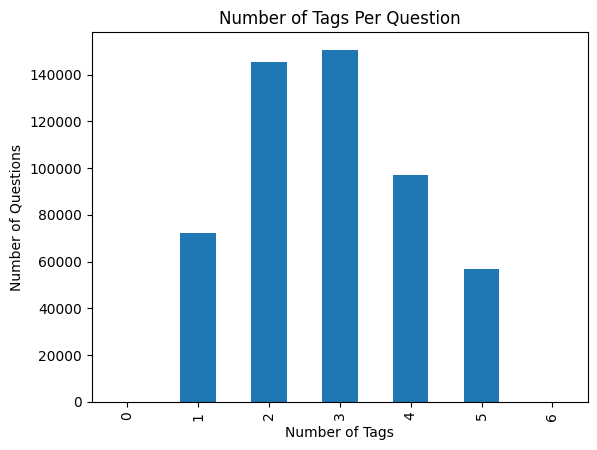

In [ ]:
df['number_of_tags'].value_counts().sort_index().plot(kind='bar')
plt.xlabel('Number of Tags')
plt.ylabel('Number of Questions')
plt.title('Number of Tags Per Question')
plt.show()

In [ ]:
print("Total unique tags:", tags.nunique())

Total unique tags: 22614


tag_list
java           74734
javascript     59642
php            51285
c#             49878
python         41388
c++            33359
android        30590
jquery         26673
html           24797
mysql          18760
c              18334
ios            17990
css            16903
arrays         14599
sql            13899
r              13660
.net           12854
objective-c    12301
string         10920
regex          10074
iphone          9009
json            7392
swift           7039
asp.net         6996
sql-server      6654
Name: count, dtype: int64


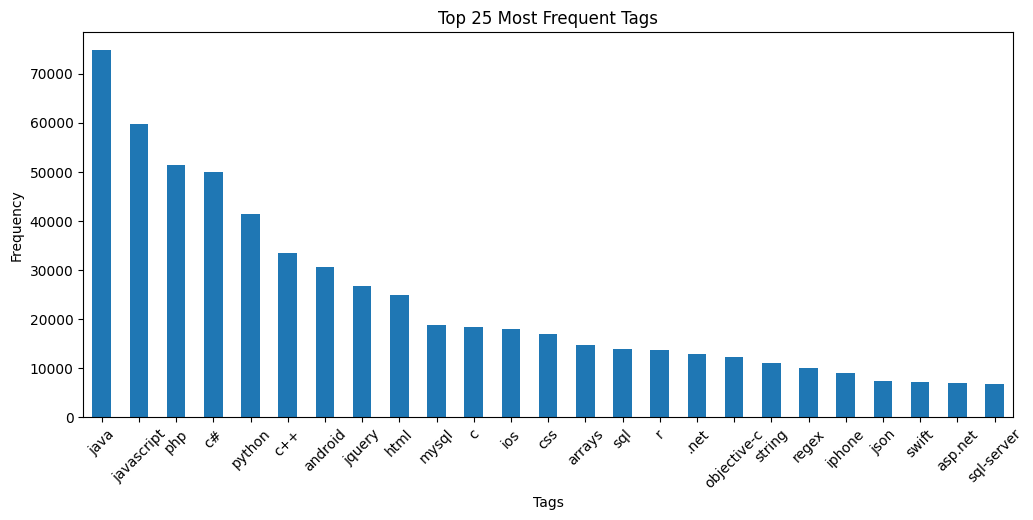

In [ ]:
top25 = tag_count.head(25)
print(top25)
top25.plot(kind='bar', figsize=(12, 5))
plt.xlabel('Tags')
plt.ylabel('Frequency')
plt.title('Top 25 Most Frequent Tags')
plt.xticks(rotation=45)
plt.show()

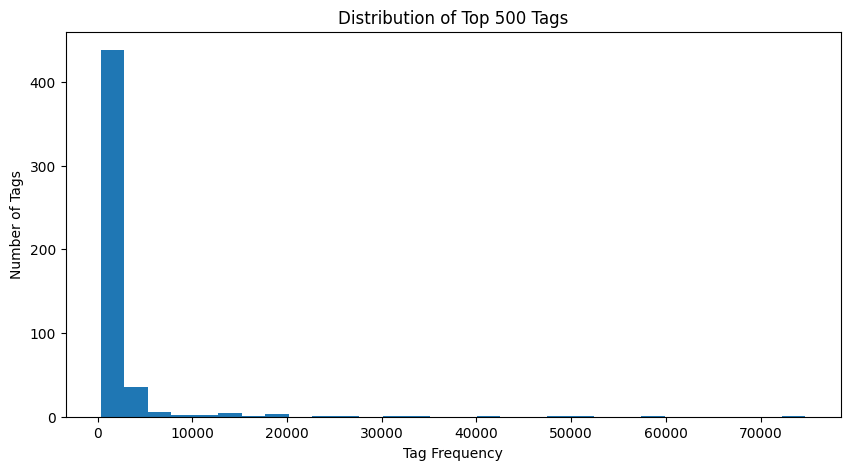

In [ ]:
top500 = tag_count.head(500)
plt.figure(figsize=(10, 5))
plt.hist(top500, bins=30)
plt.xlabel('Tag Frequency')
plt.ylabel('Number of Tags')
plt.title('Distribution of Top 500 Tags')
plt.show()

In [ ]:
df2['link_type_id'] = pd.to_numeric(df2['link_type_id'])
duplicate_ids = df2[df2['link_type_id'] == 3]['post_id'].unique()

In [ ]:
df['creation_date'] = pd.to_datetime(df['creation_date'])
df['duplicate'] = df['id'].isin(duplicate_ids)
df['month'] = df['creation_date'].dt.to_period('M')

In [ ]:
total = df.groupby('month')['id'].count()
duplicates = df.groupby('month')['duplicate'].sum()
ratio = duplicates / total * 100
ratio = ratio.loc['2008-01':'2018-12']

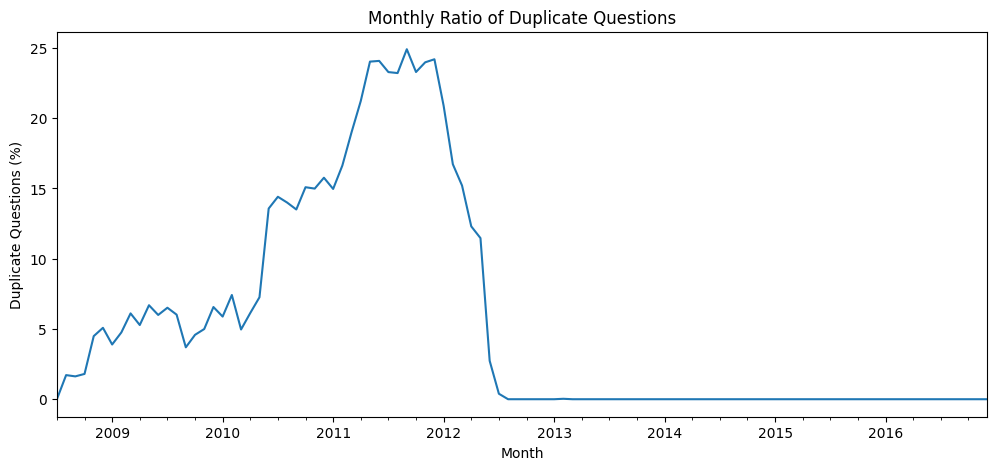

In [ ]:
plt.figure(figsize=(12, 5))
ratio.plot()
plt.xlabel('Month')
plt.ylabel('Duplicate Questions (%)')
plt.title('Monthly Ratio of Duplicate Questions')
plt.show()

In [ ]:
df['tag_list'] = df['tags'].apply( lambda x: re.findall(r'<([^>]+)>', str(x)))
tag_data = df[['tag_list', 'duplicate']].explode('tag_list')

In [ ]:
total = tag_data.groupby('tag_list')['duplicate'].count()
duplicates = tag_data.groupby('tag_list')['duplicate'].sum()
percentage = duplicates / total * 100
top20 = percentage.sort_values(ascending=False).head(20)
print(top20)

tag_list
avatar-generation       100.0
archiving               100.0
zend-navigation         100.0
zend-filter             100.0
archos                  100.0
rlwrap                  100.0
imperative-languages    100.0
resharper-5.x           100.0
air2                    100.0
ios-3.x                 100.0
numeric-textbox         100.0
windows-share           100.0
winnovative             100.0
bresenham               100.0
buildbot                100.0
application-start       100.0
basic4android           100.0
bcs                     100.0
hibernateexception      100.0
ruby-1.9.1              100.0
Name: duplicate, dtype: float64


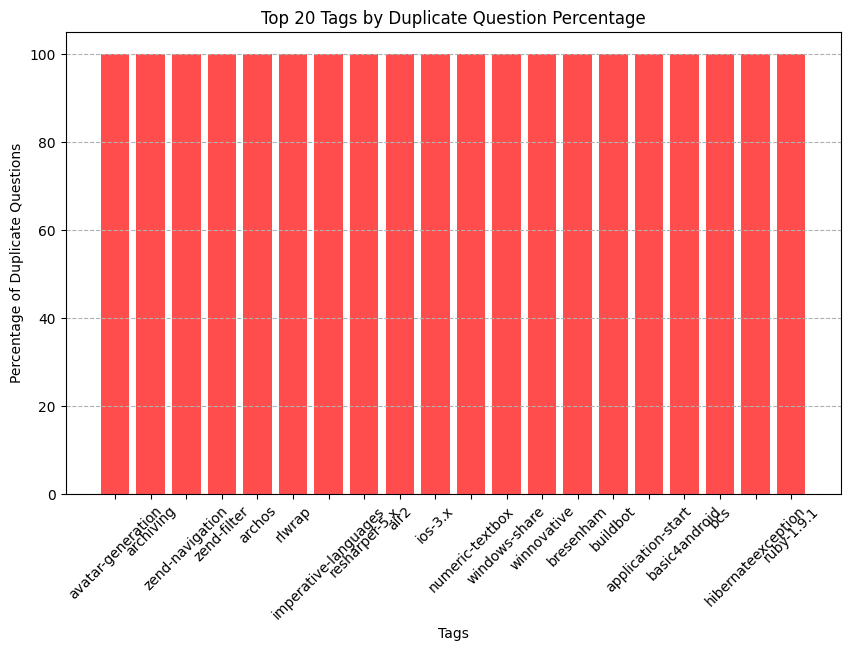

In [ ]:
plt.figure(figsize=(10, 6))
plt.bar(top20.index, top20.values, color='red', alpha=0.7)
plt.title("Top 20 Tags by Duplicate Question Percentage")
plt.xlabel("Tags")
plt.ylabel("Percentage of Duplicate Questions")
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--')
plt.show()

In [ ]:
print(df['id'].head())
print(df2['post_id'].head())
print(df['id'].dtype)
print(df2['post_id'].dtype)

0     4.0
1     6.0
2     9.0
3    11.0
4    13.0
Name: id, dtype: float64
0     109.0
1    1970.0
2    2154.0
3    2483.0
4    2572.0
Name: post_id, dtype: float64
float64
float64


In [ ]:
print(df['id'].isin(duplicate_ids).sum())
print(df['duplicate'].value_counts())

23101
duplicate
False    498783
True      23101
Name: count, dtype: int64


In [ ]:
df['id'] = pd.to_numeric(df['id'], errors='coerce')
df2['post_id'] = pd.to_numeric(df2['post_id'], errors='coerce')
duplicate_ids = df2[df2['link_type_id'] == 3]['post_id'].dropna().unique()
df['duplicate'] = df['id'].isin(duplicate_ids)
print(df['duplicate'].value_counts())

duplicate
False    498783
True      23101
Name: count, dtype: int64


In [ ]:
tag_data = df[['tags', 'duplicate']].copy()
tag_data['tags'] = tag_data['tags'].apply(lambda x: re.findall(r'<([^>]+)>', str(x)))
tag_data = tag_data.explode('tags')
total = tag_data.groupby('tags')['duplicate'].count()
duplicates = tag_data.groupby('tags')['duplicate'].sum()
percentage = duplicates / total * 100
result = pd.DataFrame({'Total Questions': total,'Duplicate Questions': duplicates,'Percentage': percentage})

In [ ]:
result = result[result['Total Questions'] >= 100]

top20 = result.sort_values(
    'Percentage', ascending=False
).head(20)

print(top20)

                       Total Questions  Duplicate Questions  Percentage
tags                                                                   
programming-languages              256                   73   28.515625
facebook-like                      138                   32   23.188406
ios4                               467                  106   22.698073
flex                               177                   40   22.598870
java-me                            138                   30   21.739130
xcode4                             224                   44   19.642857
inversion-of-control               107                   21   19.626168
blackberry                         183                   33   18.032787
open-source                        134                   24   17.910448
iphone-sdk-3.0                     109                   18   16.513761
flash                              347                   57   16.426513
interpreter                        103                   16   15

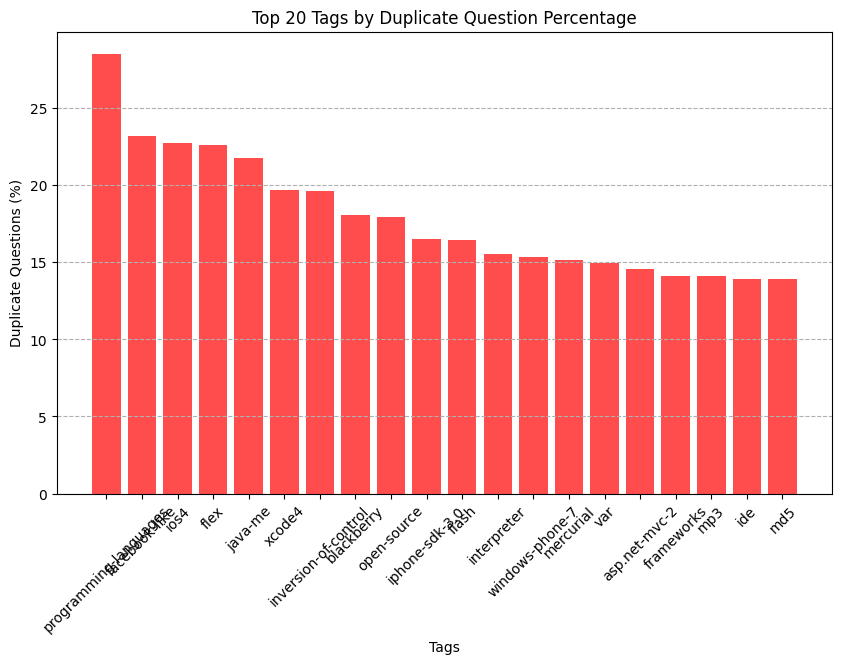

In [ ]:
plt.figure(figsize=(10, 6))
plt.bar(top20.index, top20['Percentage'],color='red', alpha=0.7)
plt.title("Top 20 Tags by Duplicate Question Percentage")
plt.xlabel("Tags")
plt.ylabel("Duplicate Questions (%)")
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--')
plt.show()

In [ ]:
history = pd.read_csv('/content/post_history.csv',
                      engine='python',
                      on_bad_lines='skip')

print(history.columns)

Index(['Unnamed: 0', 'id', 'ph_type_id', 'post_id', 'revision_guid',
       'creation_date', 'user_id', 'user_display_name', 'comment', 'text'],
      dtype='object')


In [ ]:
history.head()

,Unnamed: 0,id,ph_type_id,post_id,revision_guid,creation_date,user_id,user_display_name,comment,text
0,0,12,1,17,0421fb42-a29a-4cb2-84ba-a828725410f8,2008-08-01T05:09:55.993,2,NaN,NaN,Binary Data in MYSQL
1,1,13,3,17,0421fb42-a29a-4cb2-84ba-a828725410f8,2008-08-01T05:09:55.993,2,NaN,NaN,<database><mysql>
2,2,14,2,17,0421fb42-a29a-4cb2-84ba-a828725410f8,2008-08-01T05:09:55.993,2,NaN,NaN,How do I store binary data in mysql?
3,3,219,1,123,5dc36325-a80d-4ef2-8bd6-fde1720d7e7a,2008-08-01T16:08:52.353,78,NaN,NaN,CSV File to XML
4,4,220,3,123,5dc36325-a80d-4ef2-8bd6-fde1720d7e7a,2008-08-01T16:08:52.353,78,NaN,NaN,<csv><xml><java><>


In [ ]:
history['ph_type_id'].value_counts().sort_index()

,count
ph_type_id,
1,114422
2,114422
3,114422
4,21411
5,78699
6,38218
7,335
8,757
9,606


In [ ]:
history[history['ph_type_id'] == 10][ ['post_id', 'ph_type_id', 'creation_date', 'comment']
].head(10)

,post_id,ph_type_id,creation_date,comment
59227,34093,10,2008-09-12T11:58:39.000,2
59228,116523,10,2008-09-22T20:45:52.000,1
59229,126458,10,2008-09-30T20:42:22.000,2
59230,150743,10,2008-09-29T21:25:14.000,1
59231,153874,10,2008-09-30T16:36:19.000,1
59232,166132,10,2008-10-03T14:18:55.000,2
59233,187414,10,2008-10-09T14:13:53.000,1
59234,190531,10,2008-10-10T08:43:16.000,1
59235,201674,10,2008-10-14T15:49:30.000,1
59236,202306,10,2008-10-14T18:51:55.000,1


In [ ]:
history[history['ph_type_id'] == 10][
    ['post_id', 'creation_date', 'comment']
].head(10)

,post_id,creation_date,comment
59227,34093,2008-09-12T11:58:39.000,2
59228,116523,2008-09-22T20:45:52.000,1
59229,126458,2008-09-30T20:42:22.000,2
59230,150743,2008-09-29T21:25:14.000,1
59231,153874,2008-09-30T16:36:19.000,1
59232,166132,2008-10-03T14:18:55.000,2
59233,187414,2008-10-09T14:13:53.000,1
59234,190531,2008-10-10T08:43:16.000,1
59235,201674,2008-10-14T15:49:30.000,1
59236,202306,2008-10-14T18:51:55.000,1


In [ ]:
closed_posts = history[history['ph_type_id'] == 10]
print("Total closed-post records:", len(closed_posts))
print(closed_posts['comment'].value_counts().head(15))

Total closed-post records: 12252
comment
1    11666
4      323
3      129
2      114
7       20
Name: count, dtype: int64


In [ ]:
print(closed_posts[['post_id', 'creation_date', 'comment']].head(10).to_string(index=False))

 post_id           creation_date comment
   34093 2008-09-12T11:58:39.000       2
  116523 2008-09-22T20:45:52.000       1
  126458 2008-09-30T20:42:22.000       2
  150743 2008-09-29T21:25:14.000       1
  153874 2008-09-30T16:36:19.000       1
  166132 2008-10-03T14:18:55.000       2
  187414 2008-10-09T14:13:53.000       1
  190531 2008-10-10T08:43:16.000       1
  201674 2008-10-14T15:49:30.000       1
  202306 2008-10-14T18:51:55.000       1


/tmp/ipykernel_2155/2753194984.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  closed_posts['creation_date'] = pd.to_datetime(closed_posts['creation_date'])
/tmp/ipykernel_2155/2753194984.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  closed_posts['month'] = closed_posts['creation_date'].dt.month


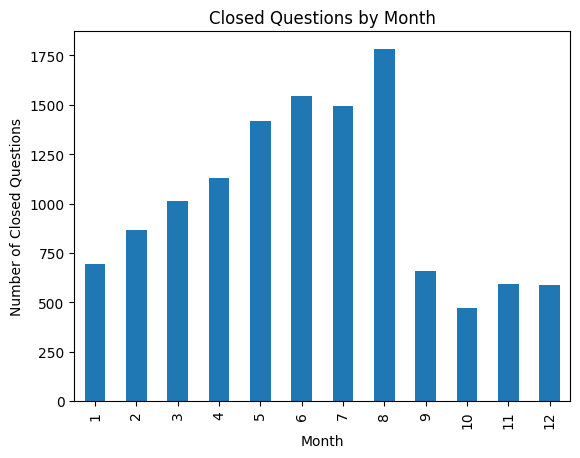

In [ ]:
closed_posts['creation_date'] = pd.to_datetime(closed_posts['creation_date'])

closed_posts['month'] = closed_posts['creation_date'].dt.month
closed_posts['month'].value_counts().sort_index().plot(kind='bar')

plt.xlabel('Month')
plt.ylabel('Number of Closed Questions')
plt.title('Closed Questions by Month')
plt.show()

In [ ]:
users = pd.read_csv('/content/users.csv')
print(users.columns)

Index(['Unnamed: 0', 'id', 'reputation', 'creation_date', 'display_name',
       'views', 'upvotes', 'downvotes', 'account_id'],
      dtype='object')


In [ ]:
duplicate_ids = df2[df2['link_type_id'] == 3]['post_id'].unique()
duplicate_users = df[df['id'].isin(duplicate_ids)]['owner_user_id']
data = users[users['id'].isin(duplicate_users)].copy()

In [ ]:
data['reputation_range'] = pd.cut(
    data['reputation'],
    bins=[-1, 100, 1000, 5000, 10000, float('inf')],
    labels=['0-100', '101-1000', '1001-5000', '5001-10000', '10000+']
)

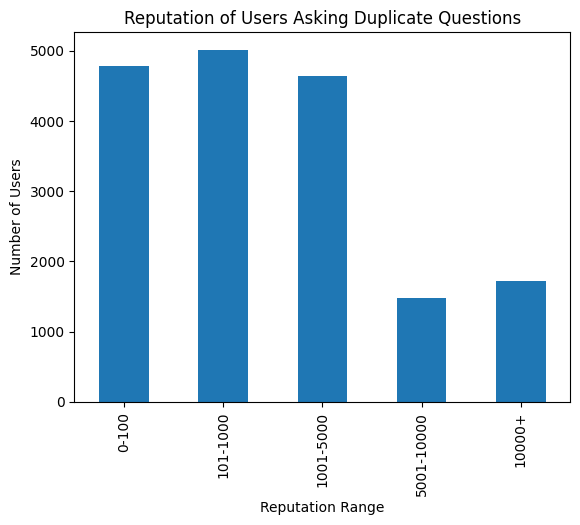

In [ ]:
data['reputation_range'].value_counts().sort_index().plot(kind='bar')
plt.xlabel('Reputation Range')
plt.ylabel('Number of Users')
plt.title('Reputation of Users Asking Duplicate Questions')
plt.show()

In [ ]:
tag_count = df['tag_list'].explode().value_counts()
top500 = tag_count.head(500)

In [ ]:
covered = df['tag_list'].apply(lambda x: any(tag in top500.index for tag in x)).sum()
print("Percentage covered:", covered / len(df) * 100, "%")

Percentage covered: 97.87998865648305 %


In [ ]:
tag_count = df['tag_list'].explode().value_counts()
top5000 = tag_count.head(5000)

In [ ]:
covered = df['tag_list'].apply(
    lambda x: any(tag in top5000.index for tag in x)).sum()
print("Percentage covered:", covered / len(df) * 100, "%")

Percentage covered: 99.84996665925762 %


In [ ]:
print(df['score'].describe())

count    521883.000000
mean         18.922172
std         111.024154
min        -146.000000
25%           0.000000
50%           2.000000
75%           9.000000
max       21775.000000
Name: score, dtype: float64


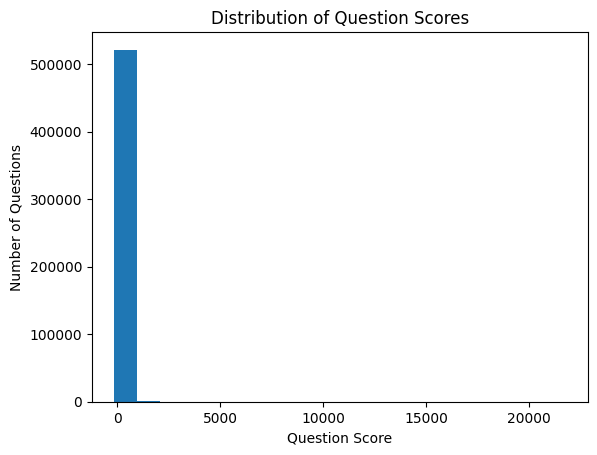

In [ ]:
plt.hist(df['score'].dropna(), bins=20)
plt.xlabel('Question Score')
plt.ylabel('Number of Questions')
plt.title('Distribution of Question Scores')
plt.show()

In [ ]:
print(df['answer_count'].value_counts().sort_index().head(10))

answer_count
0.0     61356
1.0    156234
2.0    108165
3.0     67040
4.0     41139
5.0     25618
6.0     16654
7.0     11173
8.0      7873
9.0      5564
Name: count, dtype: int64


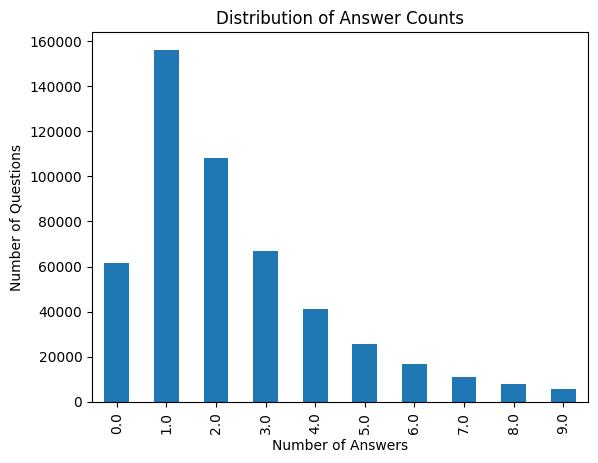

In [ ]:
df['answer_count'].value_counts().sort_index().head(10).plot(kind='bar')
plt.xlabel('Number of Answers')
plt.ylabel('Number of Questions')
plt.title('Distribution of Answer Counts')
plt.show()

In [ ]:
df[['score', 'answer_count']].head()

,score,answer_count
0,573.0,13.0
1,256.0,5.0
2,1743.0,64.0
3,1348.0,35.0
4,539.0,25.0


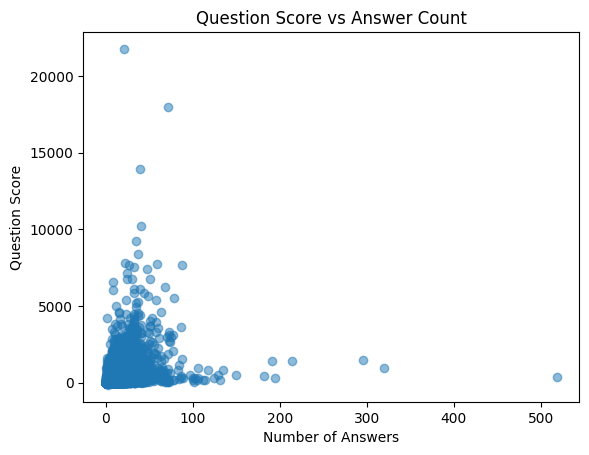

In [ ]:
plt.scatter(df['answer_count'], df['score'], alpha=0.5)
plt.xlabel('Number of Answers')
plt.ylabel('Question Score')
plt.title('Question Score vs Answer Count')
plt.show()

In [ ]:
df['creation_date'] = pd.to_datetime(df['creation_date'])
monthly = df.groupby(df['creation_date'].dt.to_period('M')).size()

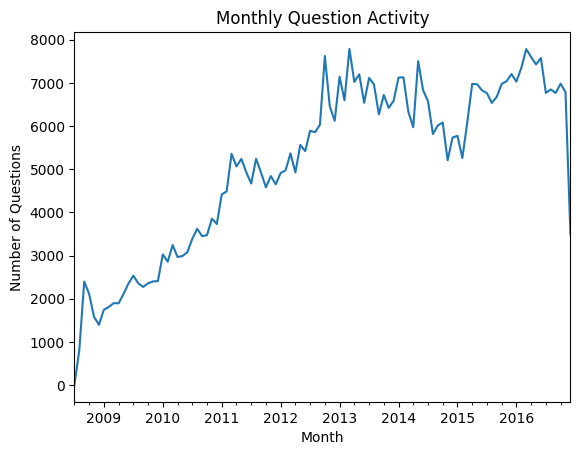

In [ ]:
monthly.plot()
plt.xlabel('Month')
plt.ylabel('Number of Questions')
plt.title('Monthly Question Activity')
plt.show()

In [ ]:
tag_data = df[['tag_list', 'score']].explode('tag_list')
top10 = tag_data['tag_list'].value_counts().head(10).index

In [ ]:
avg_score = tag_data[tag_data['tag_list'].isin(top10)].groupby('tag_list')['score'].mean()
print(avg_score)

tag_list
android       19.851226
c#            16.808874
c++           15.293174
html          18.116587
java          14.447681
javascript    21.733795
jquery        17.776141
mysql         11.174200
php            7.662026
python        23.403378
Name: score, dtype: float64


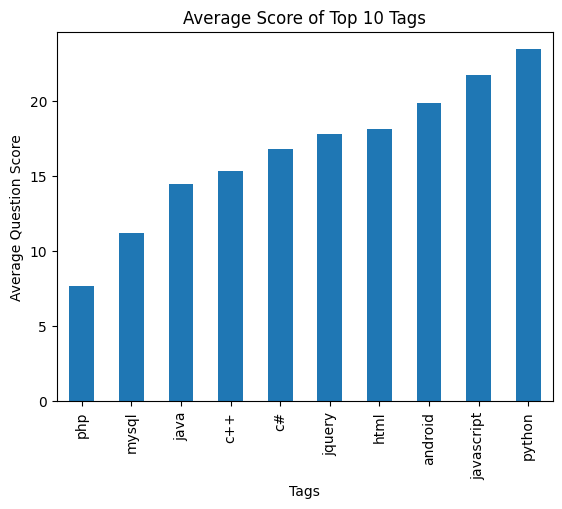

In [ ]:
avg_score.sort_values().plot(kind='bar')
plt.xlabel('Tags')
plt.ylabel('Average Question Score')
plt.title('Average Score of Top 10 Tags')
plt.show()